# Đánh giá và so sánh mô hình gom cụm

Notebook này tổng hợp kết quả của K-Means, Hierarchical Clustering và DBSCAN, tính ARI, trực quan hóa bằng PCA và đề xuất mô hình cuối.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "evaluation":
    PROJECT_ROOT = PROJECT_ROOT.parent

CLUSTER_RESULTS = PROJECT_ROOT / "clustering" / "results"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "evaluation" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_columns", None)


## 1. Đọc nhãn và kết quả tinh chỉnh

In [2]:
labels = pd.read_csv(CLUSTER_RESULTS / "labels.csv", dtype={"Customer ID": "string"})
kmeans_tuning = pd.read_csv(CLUSTER_RESULTS / "tuning_kmeans.csv")
hierarchical_tuning = pd.read_csv(CLUSTER_RESULTS / "tuning_hierarchical.csv")
dbscan_tuning = pd.read_csv(CLUSTER_RESULTS / "tuning_dbscan.csv")

print("So khach:", len(labels))
display(labels.head())


So khach: 5852


,Customer ID,kmeans,hierarchical,dbscan
0,12346,0,0,-1
1,12347,0,1,0
2,12348,1,1,0
3,12349,0,0,0
4,12350,1,2,0


### Chọn cấu hình đã lưu

Các dòng `selected=True` do notebook TV2 đánh dấu là cấu hình cuối cho từng thuật toán.

In [3]:
kmeans_selected = kmeans_tuning[kmeans_tuning["selected"]].iloc[0]
hierarchical_selected = hierarchical_tuning[hierarchical_tuning["selected"]].iloc[0]
dbscan_selected = dbscan_tuning[dbscan_tuning["selected"]].iloc[0]

print("K-Means:", kmeans_selected.to_dict())
print("Hierarchical:", hierarchical_selected.to_dict())
print("DBSCAN:", dbscan_selected.to_dict())


K-Means: {'n_clusters': 4, 'n_noise': 0, 'noise_ratio': 0.0, 'min_cluster_size': 938, 'max_cluster_size': 1982, 'silhouette': 0.2177122667555716, 'davies_bouldin': 1.4011040555691443, 'calinski_harabasz': 1778.0838787740167, 'fit_time_sec': 0.287, 'inertia': 13116.34740698332, 'elbow_candidate': False, 'selected': True, 'cv_test_wcss_mean': 2.2517853422066687, 'cv_test_wcss_std': 0.0896110342963833}
Hierarchical: {'linkage': 'ward', 'k': 5, 'n_clusters': 5, 'n_noise': 0, 'noise_ratio': 0.0, 'min_cluster_size': 568, 'max_cluster_size': 1841, 'silhouette': 0.1760971896580473, 'davies_bouldin': 1.533384969859365, 'calinski_harabasz': 1388.1905779376789, 'selected': True}
DBSCAN: {'eps': 0.8939892957889672, 'min_samples': 16, 'n_clusters': 1, 'n_noise': 345, 'noise_ratio': 0.0589542036910457, 'min_cluster_size': 5507, 'max_cluster_size': 5507, 'silhouette': nan, 'davies_bouldin': nan, 'calinski_harabasz': nan, 'fit_time_sec': 0.384, 'eps_factor': 1.0, 'knee_eps': 0.8939892957889672, 'selec

## 2. Bảng so sánh mô hình

- **Silhouette**: càng gần 1 càng tốt.
- **Davies-Bouldin**: càng nhỏ càng tốt.
- **Calinski-Harabasz**: càng lớn càng tốt.
- Với DBSCAN, loại nhãn nhiễu `-1` trước khi tính chỉ số. Cấu hình DBSCAN được TV2 đánh dấu chọn chỉ còn một cụm sau khi bỏ nhiễu nên không thể tính các chỉ số. Bảng dưới dùng cấu hình tốt nhất trong lưới có ít nhất hai cụm; cấu hình này chỉ phục vụ so sánh chỉ số, không thay thế cấu hình phát hiện ngoại biên.

In [4]:
x_path = DATA_PROCESSED / "X_scaled.csv"
X_df = pd.read_csv(x_path, dtype={"Customer ID": "string"}).set_index("Customer ID")
X_df = X_df.reindex(labels["Customer ID"])
if X_df.isna().any().any():
    raise ValueError("X_scaled.csv thiếu hoặc không khớp Customer ID trong labels.csv")
X = X_df.to_numpy()

dbscan_candidates = dbscan_tuning.loc[
    dbscan_tuning["n_clusters"].ge(2) & dbscan_tuning["silhouette"].notna()
].sort_values("silhouette", ascending=False)
if dbscan_candidates.empty:
    raise ValueError("Lưới DBSCAN không có cấu hình hợp lệ từ hai cụm trở lên.")
dbscan_eval = dbscan_candidates.iloc[0]
dbscan_eval_labels = DBSCAN(
    eps=float(dbscan_eval["eps"]),
    min_samples=int(dbscan_eval["min_samples"]),
).fit_predict(X)
dbscan_eval_mask = dbscan_eval_labels != -1
dbscan_eval_clusters = np.unique(dbscan_eval_labels[dbscan_eval_mask])
if len(dbscan_eval_clusters) < 2:
    raise ValueError("Cấu hình DBSCAN đánh giá không còn ít nhất hai cụm sau khi bỏ nhiễu.")
dbscan_eval_metrics = {
    "Silhouette": silhouette_score(X[dbscan_eval_mask], dbscan_eval_labels[dbscan_eval_mask]),
    "Davies-Bouldin": davies_bouldin_score(X[dbscan_eval_mask], dbscan_eval_labels[dbscan_eval_mask]),
    "Calinski-Harabasz": calinski_harabasz_score(X[dbscan_eval_mask], dbscan_eval_labels[dbscan_eval_mask]),
}
dbscan_eval_noise_ratio = float((dbscan_eval_labels == -1).mean())
dbscan_selected_noise_ratio = float((labels["dbscan"] == -1).mean())

comparison = pd.DataFrame([
    {
        "Mo hinh": "K-Means",
        "Cau hinh": f"k={int(kmeans_selected['n_clusters'])}",
        "So cum": int(kmeans_selected["n_clusters"]),
        "Ty le nhieu": 0.0,
        "Silhouette": kmeans_selected["silhouette"],
        "Davies-Bouldin": kmeans_selected["davies_bouldin"],
        "Calinski-Harabasz": kmeans_selected["calinski_harabasz"],
    },
    {
        "Mo hinh": "Hierarchical",
        "Cau hinh": f"{hierarchical_selected['linkage']} - k={int(hierarchical_selected['k'])}",
        "So cum": int(hierarchical_selected["n_clusters"]),
        "Ty le nhieu": 0.0,
        "Silhouette": hierarchical_selected["silhouette"],
        "Davies-Bouldin": hierarchical_selected["davies_bouldin"],
        "Calinski-Harabasz": hierarchical_selected["calinski_harabasz"],
    },
    {
        "Mo hinh": "DBSCAN (cấu hình đánh giá)",
        "Cau hinh": f"eps={dbscan_eval['eps']:.6g}, min_samples={int(dbscan_eval['min_samples'])}; cụm nhỏ nhất={int(dbscan_eval['min_cluster_size'])}",
        "So cum": len(dbscan_eval_clusters),
        "Ty le nhieu": dbscan_eval_noise_ratio,
        **dbscan_eval_metrics,
    },
])

display(comparison)
print(
    f"DBSCAN cấu hình TV2 chọn để phát hiện nhiễu: "
    f"{dbscan_selected_noise_ratio:.2%} nhiễu, {int(dbscan_selected['n_clusters'])} cụm. "
    "Các chỉ số nội bộ không xác định vì sau khi bỏ nhiễu chỉ còn một cụm."
)
print(
    "Cấu hình đánh giá trong bảng không dùng làm phân khúc chính; "
    "cụm nhỏ nhất có thể quá nhỏ để diễn giải kinh doanh."
)
results_dir = PROJECT_ROOT / "evaluation" / "results"
results_dir.mkdir(parents=True, exist_ok=True)
comparison.to_csv(results_dir / "model_comparison.csv", index=False)


,Mo hinh,Cau hinh,So cum,Ty le nhieu,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,k=4,4,0.00000,0.217712,1.401104,1778.083879
1,Hierarchical,ward - k=5,5,0.00000,0.176097,1.533385,1388.190578
2,DBSCAN (cấu hình đánh giá),"eps=0.735187, min_samples=5; cụm nhỏ nhất=5",2,0.07758,0.322704,0.648208,16.663639


DBSCAN cấu hình TV2 chọn để phát hiện nhiễu: 5.90% nhiễu, 1 cụm. Các chỉ số nội bộ không xác định vì sau khi bỏ nhiễu chỉ còn một cụm.
Cấu hình đánh giá trong bảng không dùng làm phân khúc chính; cụm nhỏ nhất có thể quá nhỏ để diễn giải kinh doanh.


## 3. Độ ổn định K-Means theo nhiều `random_state`

ARI = 1 nếu hai lần phân cụm trùng khớp hoàn toàn; giá trị gần 0 nghĩa là kết quả gần với phân cụm ngẫu nhiên. Cần file `data/processed/X_scaled.csv` từ TV1.

In [5]:
x_path = DATA_PROCESSED / "X_scaled.csv"
X = None
stability = None

if x_path.exists():
    X_df = pd.read_csv(x_path, dtype={"Customer ID": "string"}).set_index("Customer ID")
    X_df = X_df.reindex(labels["Customer ID"])
    if X_df.isna().all().all():
        raise ValueError("X_scaled.csv khong co Customer ID trung voi labels.csv")
    X = X_df.to_numpy()

    k = int(kmeans_selected["n_clusters"])
    reference_labels = labels["kmeans"].to_numpy()
    stability = []
    for seed in [0, 1, 7, 42, 100]:
        model = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=seed)
        seed_labels = model.fit_predict(X)
        stability.append({
            "random_state": seed,
            "ARI_vs_saved_labels": adjusted_rand_score(reference_labels, seed_labels),
            "inertia": model.inertia_,
        })
    stability = pd.DataFrame(stability)
    display(stability)
    stability.to_csv(results_dir / "kmeans_stability.csv", index=False)
else:
    warnings.warn(f"Khong tim thay {x_path}. Stability va PCA se duoc bo qua.")


,random_state,ARI_vs_saved_labels,inertia
0,0,0.999327,13116.353174
1,1,0.995162,13116.352103
2,7,0.998791,13116.353558
3,42,1.000000,13116.347407
4,100,0.999663,13116.351664


## 4. So sánh mức độ giống nhau giữa các thuật toán

ARI được tính giữa K-Means, Hierarchical và DBSCAN. Hai dòng cuối xem riêng kết quả DBSCAN khi gồm và khi bỏ điểm nhiễu.

In [6]:
dbscan_mask = labels["dbscan"] != -1
ari_table = pd.DataFrame([
    {"Cap mo hinh": "K-Means vs Hierarchical", "ARI": adjusted_rand_score(labels["kmeans"], labels["hierarchical"]), "Pham vi": "Toan bo khach"},
    {"Cap mo hinh": "K-Means vs DBSCAN", "ARI": adjusted_rand_score(labels["kmeans"], labels["dbscan"]), "Pham vi": "Gom nhieu -1"},
    {"Cap mo hinh": "K-Means vs DBSCAN", "ARI": adjusted_rand_score(labels.loc[dbscan_mask, "kmeans"], labels.loc[dbscan_mask, "dbscan"]), "Pham vi": "Bo nhieu -1"},
])
display(ari_table)
ari_table.to_csv(results_dir / "model_ari.csv", index=False)


,Cap mo hinh,ARI,Pham vi
0,K-Means vs Hierarchical,0.453098,Toan bo khach
1,K-Means vs DBSCAN,0.007493,Gom nhieu -1
2,K-Means vs DBSCAN,0.000000,Bo nhieu -1


## 5. PCA 2D cho từng mô hình

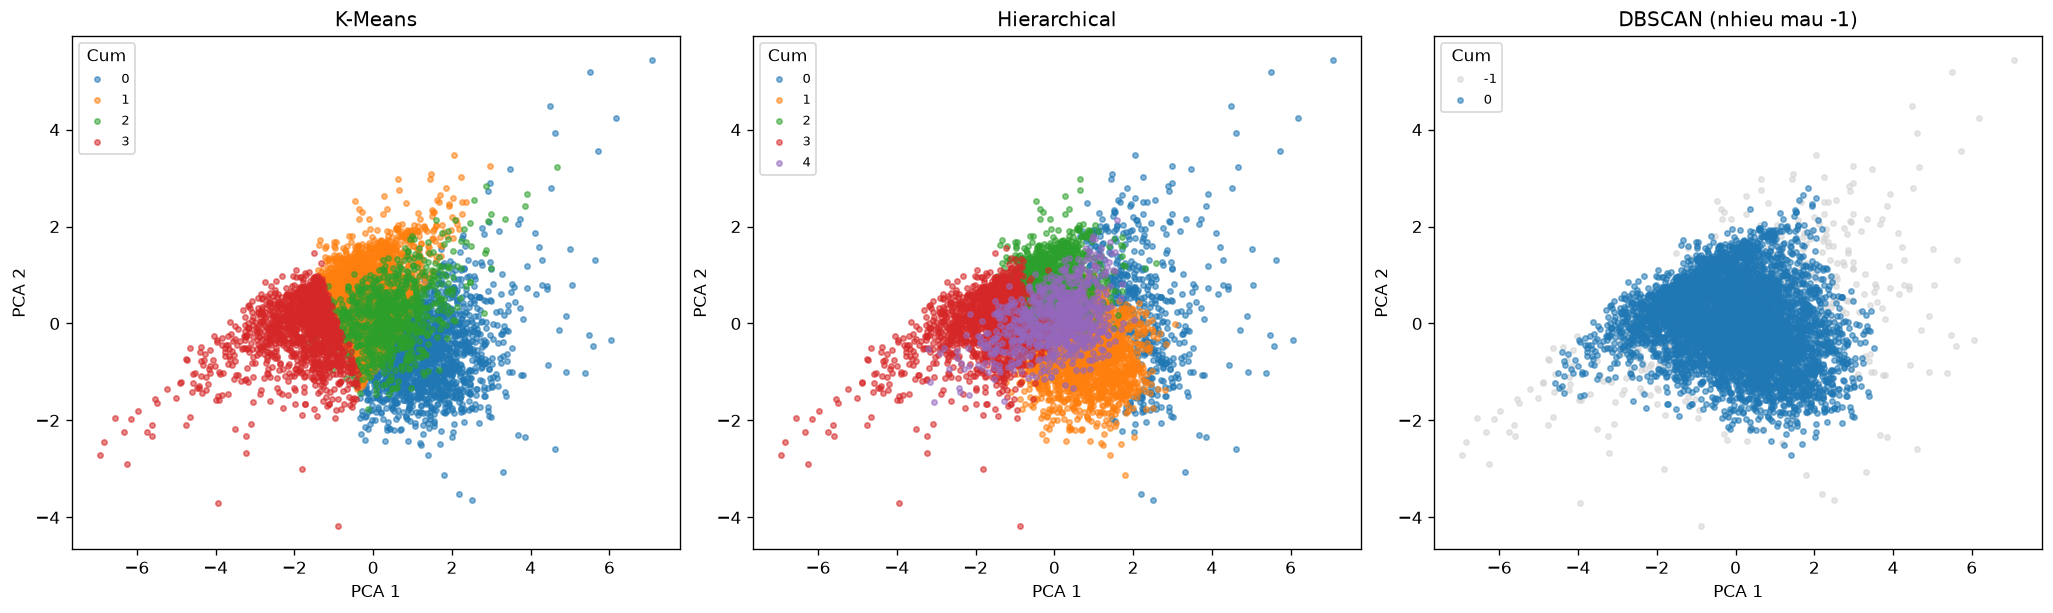

In [7]:
if X is not None:
    coords = PCA(n_components=2, random_state=42).fit_transform(X)
    fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)

    for ax, column, title in zip(
        axes,
        ["kmeans", "hierarchical", "dbscan"],
        ["K-Means", "Hierarchical", "DBSCAN (nhieu mau -1)"],
    ):
        for cluster in np.unique(labels[column].to_numpy()):
            mask = labels[column].to_numpy() == cluster
            ax.scatter(
                coords[mask, 0],
                coords[mask, 1],
                s=10,
                alpha=0.55,
                label=str(cluster),
                color="lightgray" if cluster == -1 else None,
            )
        ax.set(title=title, xlabel="PCA 1", ylabel="PCA 2")
        ax.legend(title="Cum", fontsize=8)

    fig.savefig(FIGURES_DIR / "pca_three_models.png", dpi=200, bbox_inches="tight")
    plt.show()
else:
    print("Chua tao PCA vi thieu data/processed/X_scaled.csv.")


## 6. Kết luận sơ bộ

Quyết định mô hình cuối không được dựa hoàn toàn trên một chỉ số duy nhất:

1. Chọn K-Means (k=4) làm mô hình phân khúc chính: đúng mục tiêu bốn nhóm, các cụm đủ lớn để phân tích và nhãn có thể dùng để dự đoán khách mới.
2. Chỉ so sánh các chỉ số trên cùng một không gian dữ liệu.
3. Với DBSCAN, luôn ghi rõ tỷ lệ nhiễu và đánh giá riêng nhóm ngoại biên.
4. K-Means có Silhouette 0,218, cao hơn Hierarchical Ward k=5 (0,176); ARI giữa hai mô hình là 0,453. DBSCAN được giữ làm công cụ phát hiện ngoại biên, không dùng làm mô hình persona. Cấu hình DBSCAN được bàn giao chỉ còn một cụm sau khi bỏ nhiễu; cấu hình lưới dùng để tính chỉ số có cụm nhỏ nhất rất ít khách nên không phải ứng viên phân khúc kinh doanh.

In [8]:
ari_km_hier = adjusted_rand_score(labels["kmeans"], labels["hierarchical"])

decision = pd.DataFrame({
    "Tieu chi": [
        "Ty le nhieu DBSCAN",
        "ARI K-Means - Hierarchical",
        "Mo hinh phan khuc chinh",
        "Quyet dinh mo hinh cuoi",
    ],
    "Ket qua": [
        f"{dbscan_selected_noise_ratio:.2%} ở cấu hình DBSCAN được chọn",
        f"{ari_km_hier:.4f}",
        "K-Means (k=4)",
        "DBSCAN dùng để phát hiện ngoại biên; xem thêm cluster profiling",
    ],
})
display(decision)


,Tieu chi,Ket qua
0,Ty le nhieu DBSCAN,5.90% ở cấu hình DBSCAN được chọn
1,ARI K-Means - Hierarchical,0.4531
2,Mo hinh phan khuc chinh,K-Means (k=4)
3,Quyet dinh mo hinh cuoi,DBSCAN dùng để phát hiện ngoại biên; xem thêm ...
